In [ ]:
# 下载人脸数据集

In [3]:
from sklearn.datasets import fetch_lfw_people

# 下载数据集，设置最小人脸数量为70，并调整图像大小为0.4倍
lfw_people = fetch_lfw_people(data_home='./', min_faces_per_person=70, resize=0.4)

# 查看数据的基本信息
print("数据形状:", lfw_people.data.shape)
print("目标标签:", lfw_people.target_names)


数据形状: (1288, 1850)
目标标签: ['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Tony Blair']


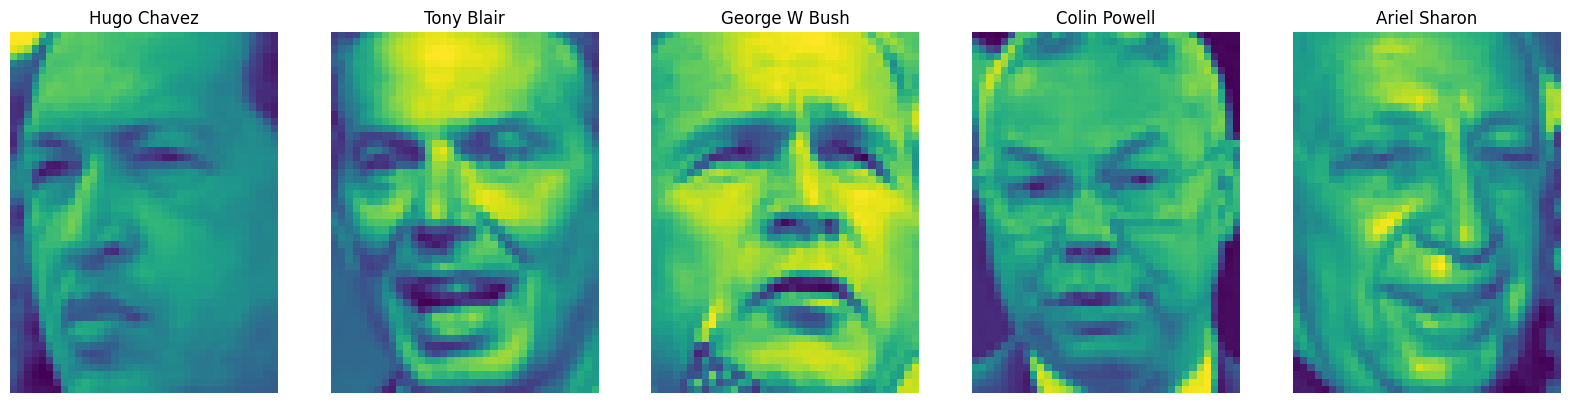

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
# 可视化部分人脸图像
fig, axes = plt.subplots(1, 5, figsize=(20, 10))
for i in range(5):
    axes[i].imshow(lfw_people.images[i])
    axes[i].set_title(lfw_people.target_names[lfw_people.target[i]])
    axes[i].axis('off')
plt.show()

In [7]:
# 由于数据集有1288样本，每个样本有1850个特征
# 避免特征远大于样本数，导致维度灾难
# 使用PCA进行降维
from sklearn.decomposition import PCA
pca = PCA(n_components=150, whiten=True, random_state=42)
X_pca = pca.fit_transform(lfw_people.data)
print("降维后数据形状:", X_pca.shape)

降维后数据形状: (1288, 150)


In [12]:
# 训练SVM分类器
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.svm import SVC

kf = KFold(n_splits=5, shuffle=True, random_state=42)
X = X_pca
y = lfw_people.target

svm_clf = SVC(C=10, gamma=0.001, kernel='rbf', class_weight='balanced', random_state=42)
y_pred = cross_val_predict(svm_clf, X, y, cv=kf)


分类准确率: 0.8269
分类报告:
                    precision    recall  f1-score   support

     Ariel Sharon       0.75      0.74      0.75        77
     Colin Powell       0.74      0.85      0.79       236
  Donald Rumsfeld       0.79      0.76      0.77       121
    George W Bush       0.90      0.88      0.89       530
Gerhard Schroeder       0.75      0.79      0.77       109
      Hugo Chavez       0.90      0.73      0.81        71
       Tony Blair       0.82      0.78      0.80       144

         accuracy                           0.83      1288
        macro avg       0.81      0.79      0.80      1288
     weighted avg       0.83      0.83      0.83      1288



/root/miniconda3/envs/universe/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/root/miniconda3/envs/universe/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/root/miniconda3/envs/universe/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 26631 (\N{CJK UNIFIED IDEOGRAPH-6807}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/root/miniconda3/envs/universe/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 31614 (\N{CJK UNIFIED IDEOGRAPH-7B7E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/root/miniconda3/envs/universe/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: User

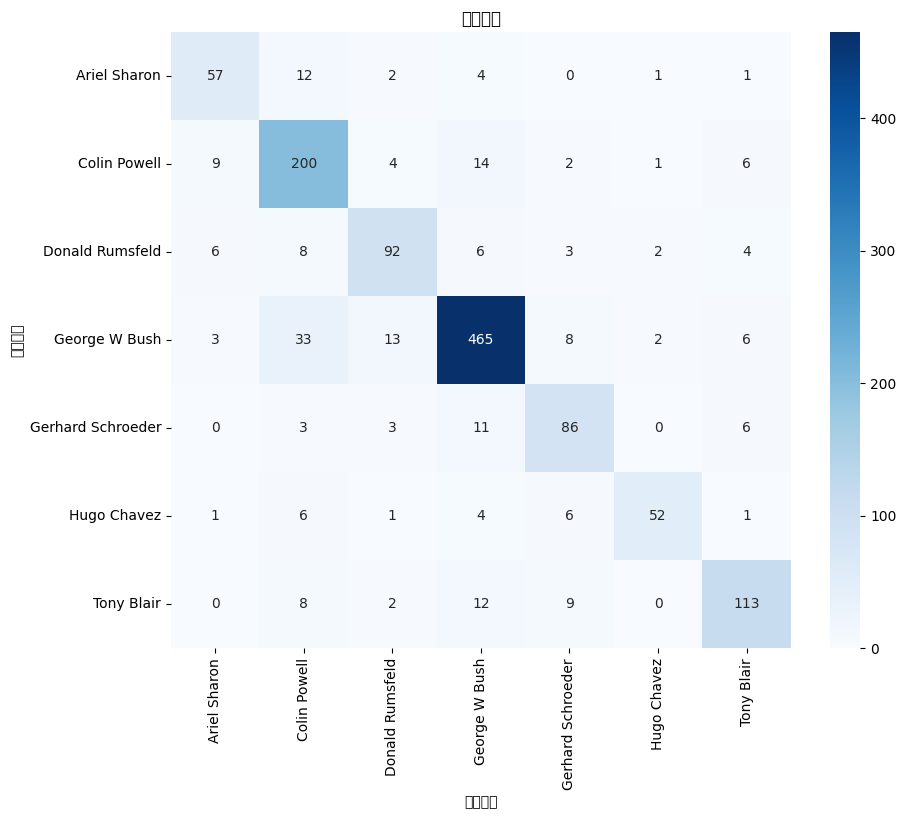

In [13]:
# 评估模型
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
accuracy = accuracy_score(y, y_pred)
print(f"分类准确率: {accuracy:.4f}")
print("分类报告:\n", classification_report(y, y_pred, target_names=lfw_people.target_names))
cm = confusion_matrix(y, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=lfw_people.target_names, yticklabels=lfw_people.target_names, cmap='Blues')
plt.xlabel('预测标签')
plt.ylabel('真实标签')
plt.title('混淆矩阵')
plt.show()